# In-the-Wild – dataset check

This notebook checks whether the In-the-Wild files on disk match what is written in the documentation: the main paper (Müller et al., arXiv version 5), the Hugging Face dataset card `README.md` and the Fraunhofer dataset page. All expected values and their sources are collected in `draft_notes_files/04_in_the_wild/04_in_the_wild_detailed.md` and `docs/04_in_the_wild.md`.

**How to use it**

- Run the cells from top to bottom.
- The notebook only **reads** the data – nothing in `datasets/` is changed. It reads only the headers of the audio files (`soundfile.info`), not the sound itself.
- Every check prints one line:
  - `[OK]` – the files match the documentation,
  - `[DIFF]` – the files do not match the documentation,
  - `[INFO]` – an observation, there is nothing to compare with.

**Output files**

In `outputs/04_in_the_wild_dataset_exploration_output/` (not committed to git):

- `audio_info.csv` – properties of every audio file (step 8a),
- `checks.csv` – table of all checks (step 9).

In `results/04_in_the_wild/04_in_the_wild_dataset_exploration_output/` (committed to git):

- `dataset_exploration_report.md` – report with the results of all steps (step 10).

### Setup – paths and settings

**What it does:** Loads the libraries, finds the project folder and sets the paths to the dataset (`datasets/04_in_the_wild`), to the outputs folder for working files and to the results folder for the report. The whole dataset comes in one archive, `release_in_the_wild.zip`, which unpacks to the flat folder `release_in_the_wild/`. It also defines the names of the columns and labels of `meta.csv` and short names of the sources.

**Why:** All the next cells use these paths and names. The paths are relative to the project folder, so the notebook works on any computer without changes. The authors do not document the folder, the columns or the label values – the names are taken from the detailed note (sections 4 and 9), which describes the downloaded files.

In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise FileNotFoundError("pyproject.toml not found")


REPO_ROOT = find_repo_root(Path.cwd())
DATA_DIR = REPO_ROOT / "datasets" / "04_in_the_wild"
AUDIO_DIR = DATA_DIR / "release_in_the_wild"
META_FILE = AUDIO_DIR / "meta.csv"
NOTEBOOK_NAME = "04_in_the_wild_dataset_exploration"
OUTPUTS_DIR = REPO_ROOT / "outputs" / f"{NOTEBOOK_NAME}_output"
RESULTS_DIR = REPO_ROOT / "results" / "04_in_the_wild" / f"{NOTEBOOK_NAME}_output"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# names from the detailed note, sections 4 and 9 (not documented by the authors)
NON_AUDIO_FILES = {"attribution.txt", "meta.csv"}
COLUMNS = ["file", "speaker", "label"]
LABELS = ["bona-fide", "spoof"]

# short names of the sources
PAPER = "main paper (arXiv v5)"
CARD = "README.md (Hugging Face dataset card)"
WEB = "Fraunhofer dataset page (web only)"
NOTE = "detailed note (not documented by the authors)"
NOT_STATED = "not stated (observation)"

print("Data folder:", DATA_DIR.relative_to(REPO_ROOT), "| exists:", DATA_DIR.exists())
print("Audio folder:", AUDIO_DIR.relative_to(REPO_ROOT), "| exists:", AUDIO_DIR.exists())

Data folder: datasets/04_in_the_wild | exists: True
Audio folder: datasets/04_in_the_wild/release_in_the_wild | exists: True


### Check list – helper function

**What it does:** Defines `add_check`, a small function that compares an **expected** value (from the documentation) with a **measured** value (from the files on disk). It prints `[OK]` if they match, `[DIFF]` if they do not, and `[INFO]` if there is nothing to compare with (only an observation). Every result is saved in the list `checks`.

**Why:** All results are collected in one place, so at the end they can be shown in one table and written to the report.

In [2]:
checks = []


def add_check(check: str, source: str, expected, measured) -> None:
    ok = None if expected is None else expected == measured
    checks.append(
        {
            "check": check,
            "source": source,
            "expected": expected,
            "measured": measured,
            "ok": ok,
        }
    )
    status = "INFO" if ok is None else ("OK" if ok else "DIFF")
    print(f"[{status}] {check}: expected={expected!r}, measured={measured!r}")

### Step 1 – Folder structure

**What it does:** Checks that the archive was unpacked to `release_in_the_wild/` (the dataset card, *"Option 2: wget"*, ends with `unzip release_in_the_wild.zip`), that this folder contains only the audio files, `meta.csv` and `attribution.txt`, without subfolders (detailed note, section 4), and that the audio files are WAV files – the paper says that the clips *"are converted to 'wav' after downloading"* (PDF p. 2, section 3). Hidden system files (for example `.DS_Store`) are ignored.

**Why:** Confirms that the archive was downloaded and unpacked completely.

In [3]:
found_top = sorted(p.name for p in DATA_DIR.iterdir() if not p.name.startswith("."))
print("Data folder contains:", found_top)

add_check(
    "release_in_the_wild/ folder exists",
    f"{CARD}, Option 2 (unzip release_in_the_wild.zip)",
    True,
    AUDIO_DIR.is_dir(),
)

items = [p for p in AUDIO_DIR.iterdir() if not p.name.startswith(".")]
files = [p for p in items if p.is_file()]
add_check(
    "Files other than .wav in release_in_the_wild/",
    f"{NOTE}, section 4",
    NON_AUDIO_FILES,
    {p.name for p in files if p.suffix != ".wav"},
)
add_check(
    "Subfolders in release_in_the_wild/",
    f"{NOTE}, section 4",
    0,
    sum(p.is_dir() for p in items),
)
add_check(
    "Extension of the audio files",
    f"{PAPER}, PDF p. 2, section 3",
    {".wav"},
    {p.suffix for p in files if p.name not in NON_AUDIO_FILES},
)

Data folder contains: ['README.md', 'release_in_the_wild', 'release_in_the_wild.zip']
[OK] release_in_the_wild/ folder exists: expected=True, measured=True
[OK] Files other than .wav in release_in_the_wild/: expected={'meta.csv', 'attribution.txt'}, measured={'meta.csv', 'attribution.txt'}
[OK] Subfolders in release_in_the_wild/: expected=0, measured=0
[OK] Extension of the audio files: expected={'.wav'}, measured={'.wav'}


### Step 2 – Load the label file

**What it does:** Reads `release_in_the_wild/meta.csv` into a table. Each row is one clip: the name of the audio file (`file`), the name of the speaker (`speaker`) and the label, real (`bona-fide`) or fake (`spoof`). All values are read as text.

**Why:** All the next checks use this table. In In-the-Wild the labels are in the same archive as the audio.

In [4]:
meta = pd.read_csv(META_FILE, dtype=str, keep_default_na=False)
print("Rows in meta.csv:", len(meta))
display(meta)

Rows in meta.csv: 31779


,file,speaker,label
0,0.wav,Alec Guinness,spoof
1,1.wav,Alec Guinness,spoof
2,2.wav,Barack Obama,spoof
3,3.wav,Alec Guinness,spoof
4,4.wav,Christopher Hitchens,bona-fide
...,...,...,...
31774,31774.wav,Boris Johnson,bona-fide
31775,31775.wav,Donald Trump,bona-fide
31776,31776.wav,Donald Trump,bona-fide
31777,31777.wav,Alan Watts,bona-fide


### Step 3 – Format of the label file

**What it does:** Checks the column names (detailed note, section 9.1 – the authors do not describe the file), the label values, duplicated file names and empty cells. The authors use other words for the labels than the file: the paper speaks of *"bona-fide and spoofed audio"* (PDF p. 2, Figure 1 caption) and the dataset card of *"Deepfake / Genuine"*. Both checks are kept – they show a DIFF because the file uses `spoof` (and `bona-fide`).

**Why:** If the label file were broken, every later result would be wrong.

In [5]:
add_check("meta.csv: column names", f"{NOTE}, section 9.1", COLUMNS, list(meta.columns))
add_check(
    "Label values (paper)",
    f"{PAPER}, PDF p. 2, Figure 1 caption",
    {"bona-fide", "spoofed"},
    set(meta["label"]),
)
add_check(
    "Label values (dataset card)",
    f"{CARD}, Task (Deepfake / Genuine)",
    {"Deepfake", "Genuine"},
    set(meta["label"]),
)
add_check("Duplicated file names", "-", 0, int(meta["file"].duplicated().sum()))
add_check("Empty cells", "-", 0, int((meta == "").sum().sum()))

[OK] meta.csv: column names: expected=['file', 'speaker', 'label'], measured=['file', 'speaker', 'label']
[DIFF] Label values (paper): expected={'bona-fide', 'spoofed'}, measured={'bona-fide', 'spoof'}
[DIFF] Label values (dataset card): expected={'Genuine', 'Deepfake'}, measured={'bona-fide', 'spoof'}
[OK] Duplicated file names: expected=0, measured=0
[OK] Empty cells: expected=0, measured=0


### Step 4 – Number of clips per label

**What it does:** Counts the real (`bona-fide`) and fake (`spoof`) clips. The paper and the dataset pages give hours (step 8b), but not the number of clips (detailed note, section 7), so the counts are only observations.

**Why:** Shows the class balance – the share of fake clips matters when clips are sampled for experiments.

In [6]:
clip_counts = meta["label"].value_counts().reindex(LABELS, fill_value=0)
counts = pd.DataFrame(
    {
        "clips": [*clip_counts.tolist(), int(clip_counts.sum())],
        "share_%": [*(100 * clip_counts / clip_counts.sum()).round(2).tolist(), 100.0],
    },
    index=[*LABELS, "all"],
)
display(counts)

NO_CLIPS = "not stated in the paper or on the pages (detailed note, section 7)"
add_check(
    "bona-fide / spoof: clips",
    NO_CLIPS,
    None,
    (int(clip_counts["bona-fide"]), int(clip_counts["spoof"])),
)
add_check("All clips", NO_CLIPS, None, int(clip_counts.sum()))
add_check("Share of spoof clips [%]", NO_CLIPS, None, float(counts.loc["spoof", "share_%"]))

,clips,share_%
bona-fide,19963,62.82
spoof,11816,37.18
all,31779,100.00


[INFO] bona-fide / spoof: clips: expected=None, measured=(19963, 11816)
[INFO] All clips: expected=None, measured=31779
[INFO] Share of spoof clips [%]: expected=None, measured=37.18


### Step 5 – Speakers

**What it does:** Counts the different speakers and compares the number with the paper (PDF p. 1, section 1; PDF p. 2, Figure 1: *"For n = 58 celebrities and politicians"*), the Fraunhofer page and the dataset card – all three give 58. It checks that every speaker has real and fake clips (Figure 1 caption: *"we collected both bona-fide and spoofed audio"*), shows the number of clips per speaker and label, and their minimum, median and maximum.

**Why:** Confirms that all speakers are present. If the share of fake clips differs a lot between speakers, the speaker could become a shortcut.

In [7]:
per_speaker = pd.crosstab(meta["speaker"], meta["label"]).reindex(columns=LABELS, fill_value=0)
per_speaker["total"] = per_speaker.sum(axis=1)
per_speaker["spoof_%"] = (100 * per_speaker["spoof"] / per_speaker["total"]).round(1)
display(per_speaker)

add_check(
    "Number of speakers",
    f"{PAPER}, PDF p. 1, section 1 and PDF p. 2, Figure 1; {WEB}; {CARD}",
    58,
    meta["speaker"].nunique(),
)
add_check(
    "Every speaker has bona-fide and spoof clips",
    f"{PAPER}, PDF p. 2, Figure 1 caption",
    True,
    bool((per_speaker[LABELS] > 0).all().all()),
)

speaker_stats = per_speaker[["total", *LABELS]].agg(["min", "median", "max"]).T
display(speaker_stats)
for column, row in speaker_stats.iterrows():
    add_check(
        f"Clips per speaker ({column}): min / median / max",
        NOT_STATED,
        None,
        (int(row["min"]), float(row["median"]), int(row["max"])),
    )

label,bona-fide,spoof,total,spoof_%
speaker,,,,
2Pac,59,101,160,63.1
Adam Driver,80,137,217,63.1
Alan Watts,86,292,378,77.2
Alec Guinness,1907,1718,3625,47.4
Alexandria Ocasio-Cortez,290,100,390,25.6
Arnold Schwarzenegger,243,108,351,30.8
Ayn Rand,1389,1104,2493,44.3
Barack Obama,3302,334,3636,9.2
Bernie Sanders,1623,1254,2877,43.6


[DIFF] Number of speakers: expected=58, measured=54
[OK] Every speaker has bona-fide and spoof clips: expected=True, measured=True


,min,median,max
label,,,
total,14.0,212.5,3636.0
bona-fide,3.0,96.0,3302.0
spoof,4.0,98.0,1718.0


[INFO] Clips per speaker (total): min / median / max: expected=None, measured=(14, 212.5, 3636)
[INFO] Clips per speaker (bona-fide): min / median / max: expected=None, measured=(3, 96.0, 3302)
[INFO] Clips per speaker (spoof): min / median / max: expected=None, measured=(4, 98.0, 1718)


### Step 6 – Splits (skipped)

In-the-Wild has no splits: *"This dataset is intended as evaluation data"* (paper, PDF p. 2, section 3), and `meta.csv` has no split column – so there is nothing to check.

### Step 7 – Audio files vs labels

**What it does:** Collects the `.wav` files in `release_in_the_wild/` and compares them with `meta.csv`: labelled files missing on disk and audio files without a label. Duplicated names across folders are not checked, because all audio files are in one folder.

**Why:** Every labelled clip must exist as a file, and every audio file must have a label.

In [8]:
wav_paths = {p.name: p for p in AUDIO_DIR.glob("*.wav")}
on_disk = set(wav_paths)
in_labels = set(meta["file"])

print(f"Audio files on disk = {len(on_disk)}, rows in meta.csv = {len(in_labels)}")
add_check("Labelled files missing on disk", "-", 0, len(in_labels - on_disk))
add_check("Audio files without a label", "-", 0, len(on_disk - in_labels))

Audio files on disk = 31779, rows in meta.csv = 31779
[OK] Labelled files missing on disk: expected=0, measured=0
[OK] Audio files without a label: expected=0, measured=0


### Step 8a – Read the audio file properties

**What it does:** Reads only the header of every audio file (not the sound itself): format, sample rate, bit depth (subtype), number of channels and length. The result is saved to `outputs/04_in_the_wild_dataset_exploration_output/audio_info.csv`; the next time the notebook loads this file instead of reading all clips again. **The first run takes a few minutes (31,779 files).**

**Why:** These properties are needed for the technical checks in the next cell and later for the table of recording features (silence, loudness, bandwidth, duration).

In [9]:
INFO_CACHE = OUTPUTS_DIR / "audio_info.csv"

if INFO_CACHE.exists():
    info = pd.read_csv(INFO_CACHE, dtype={"file": str})
    print("Loaded from cache:", INFO_CACHE.relative_to(REPO_ROOT))
else:
    rows = []
    paths = [wav_paths[name] for name in sorted(in_labels & on_disk)]
    print(f"Reading {len(paths)} files ...")
    for path in paths:
        meta_info = sf.info(path)
        rows.append(
            {
                "file": path.name,
                "format": meta_info.format,
                "subtype": meta_info.subtype,
                "samplerate": meta_info.samplerate,
                "channels": meta_info.channels,
                "frames": meta_info.frames,
            }
        )
    info = pd.DataFrame(rows)
    info["duration_s"] = info["frames"] / info["samplerate"]
    info.to_csv(INFO_CACHE, index=False)
    print("Saved to:", INFO_CACHE.relative_to(REPO_ROOT))

audio = info.merge(meta, on="file", how="inner")
print("Audio files with labels:", len(audio))

Reading 31779 files ...
Saved to: outputs/04_in_the_wild_dataset_exploration_output/audio_info.csv
Audio files with labels: 31779


### Step 8b – Check the audio file properties

**What it does:**

- Checks that all files are WAV with a sample rate of 16 kHz – *"All recordings were downsampled to 16 kHz"* (paper, PDF p. 2, section 3). Bit depth and channels are not documented, so they are only observations; the table shows every value found and the number of files.
- Adds up the hours per label and compares them with the documentation. The sources do not agree for bona fide, so there is one check per value: 20.7 h (paper text, PDF pp. 1–2; dataset card) and 20.8 h (paper, Figure 1 caption; Fraunhofer page). Spoof: 17.2 h, all: 37.9 h. The hours are rounded to one decimal place.
- Compares the mean clip length with the paper (*"The clips have an average length of 4.3 seconds"*, PDF p. 2) and the mean minutes per speaker with Figure 1 (*"23 minutes of bona-fide and 18 minutes of spoofed audio per speaker"*). The minutes are computed as hours of the label × 60 / number of speakers in `meta.csv`; the paper does not say how it computed them.
- Shows duration statistics per label.

**Why:** Confirms the technical description of the dataset. A clear difference in duration between real and fake clips could be a shortcut that detectors use.

In [10]:
add_check("File format", f"{PAPER}, PDF p. 2, section 3", {"WAV"}, set(audio["format"].tolist()))
add_check(
    "Sample rate [Hz]",
    f"{PAPER}, PDF p. 2, section 3",
    {16000},
    set(audio["samplerate"].tolist()),
)
add_check("Bit depth (subtype)", NOT_STATED, None, set(audio["subtype"].tolist()))
add_check("Number of channels", NOT_STATED, None, set(audio["channels"].tolist()))

PROPERTIES = ["format", "subtype", "samplerate", "channels"]
property_values = pd.concat(
    [
        audio[column]
        .value_counts()
        .rename_axis("value")
        .reset_index(name="files")
        .assign(property=column)
        for column in PROPERTIES
    ]
).set_index(["property", "value"])
display(property_values)

hours = audio.groupby("label")["duration_s"].sum().reindex(LABELS) / 3600
hours_table = hours.to_frame("hours")
hours_table.loc["all"] = hours.sum()
display(hours_table.round(2))

bona_fide_hours = round(float(hours["bona-fide"]), 1)
add_check(
    "bona-fide: hours",
    f"{PAPER}, PDF p. 1, section 1 and PDF p. 2, section 3; {CARD}",
    20.7,
    bona_fide_hours,
)
add_check(
    "bona-fide: hours",
    f"{PAPER}, PDF p. 2, Figure 1 caption; {WEB}",
    20.8,
    bona_fide_hours,
)
add_check(
    "spoof: hours",
    f"{PAPER}, PDF pp. 1-2; {WEB}; {CARD}",
    17.2,
    round(float(hours["spoof"]), 1),
)
add_check(
    "All: hours",
    f"{PAPER}, PDF p. 1, abstract and PDF p. 2, section 3; {CARD}",
    37.9,
    round(float(hours.sum()), 1),
)
add_check(
    "Mean clip duration [s]",
    f"{PAPER}, PDF p. 2, section 3",
    4.3,
    round(float(audio["duration_s"].mean()), 1),
)

minutes_per_speaker = hours * 60 / meta["speaker"].nunique()
for label, expected in {"bona-fide": 23, "spoof": 18}.items():
    add_check(
        f"{label}: mean minutes per speaker",
        f"{PAPER}, PDF p. 2, Figure 1 caption; {WEB}",
        expected,
        round(float(minutes_per_speaker[label])),
    )

duration_stats = audio.groupby("label")["duration_s"].describe().reindex(LABELS)
duration_stats["count"] = duration_stats["count"].astype(int)
display(duration_stats.round(2))

median_duration = round(float(audio["duration_s"].median()), 2)
add_check("Median duration [s]", NOT_STATED, None, median_duration)

[OK] File format: expected={'WAV'}, measured={'WAV'}
[OK] Sample rate [Hz]: expected={16000}, measured={16000}
[INFO] Bit depth (subtype): expected=None, measured={'FLOAT'}
[INFO] Number of channels: expected=None, measured={1}


,,files
property,value,
format,WAV,31779
subtype,FLOAT,31779
samplerate,16000,31779
channels,1,31779


,hours
label,
bona-fide,20.76
spoof,17.09
all,37.85


[DIFF] bona-fide: hours: expected=20.7, measured=20.8
[OK] bona-fide: hours: expected=20.8, measured=20.8
[DIFF] spoof: hours: expected=17.2, measured=17.1
[OK] All: hours: expected=37.9, measured=37.9
[OK] Mean clip duration [s]: expected=4.3, measured=4.3
[OK] bona-fide: mean minutes per speaker: expected=23, measured=23
[DIFF] spoof: mean minutes per speaker: expected=18, measured=19


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
bona-fide,19963,3.74,2.78,0.44,1.97,2.99,4.57,24.95
spoof,11816,5.21,3.97,0.55,2.42,4.05,6.68,24.99


[INFO] Median duration [s]: expected=None, measured=3.27


### Step 8c – Duration histograms

**What it does:** Draws the same three charts as for the ASVspoof datasets (density, number of clips, percent), with real and fake clips on top of each other. All clips are used – In-the-Wild has no subsets.

**Why:** Makes it easy to see at a glance whether real and fake clips differ in length.

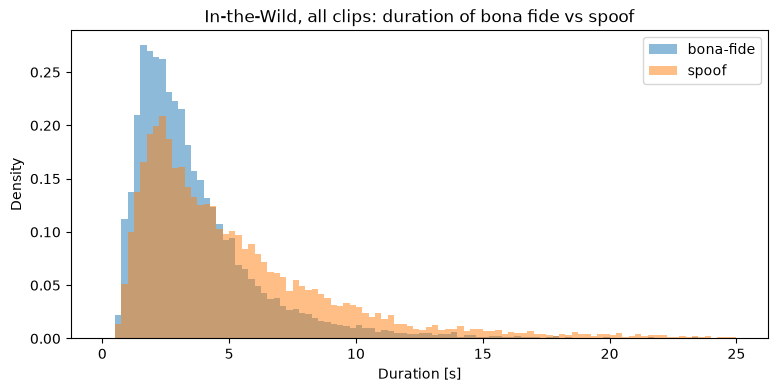

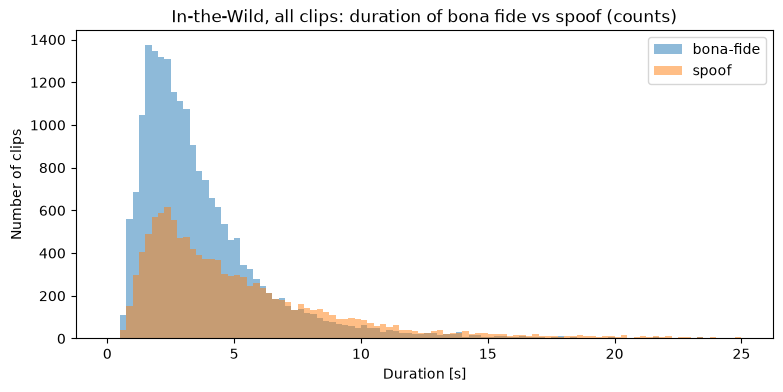

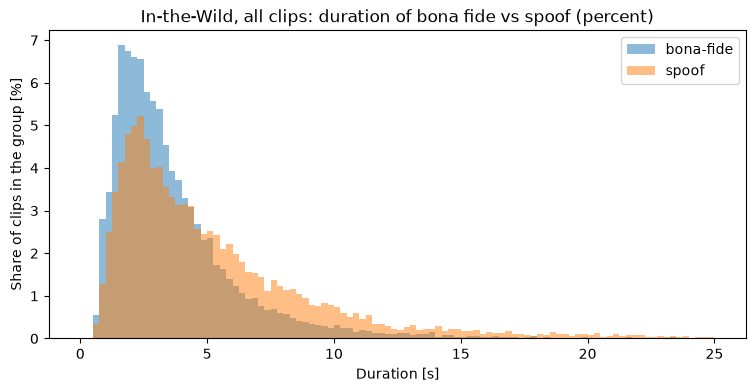

In [11]:
max_duration = float(np.ceil(audio["duration_s"].max()))
bins = np.linspace(0, max_duration, 101)


def plot_durations(data: pd.DataFrame, name: str) -> None:
    variants = [
        ("density", "Density", ""),
        ("counts", "Number of clips", " (counts)"),
        ("percent", "Share of clips in the group [%]", " (percent)"),
    ]
    for variant, y_label, title_end in variants:
        fig, ax = plt.subplots(figsize=(9, 4))
        for label, group in data.groupby("label"):
            weights = [100 / len(group)] * len(group) if variant == "percent" else None
            ax.hist(
                group["duration_s"],
                bins=bins,
                alpha=0.5,
                density=variant == "density",
                weights=weights,
                label=label,
            )
        ax.set_xlabel("Duration [s]")
        ax.set_ylabel(y_label)
        ax.set_title(f"In-the-Wild, {name}: duration of bona fide vs spoof{title_end}")
        ax.legend()
        plt.show()


plot_durations(audio, "all clips")

### Step 9 – Summary of all checks

**What it does:** Shows all checks in one table with their status (OK, DIFF, INFO), lists only the differences and saves the table to `outputs/04_in_the_wild_dataset_exploration_output/checks.csv`.

**Why:** One place to see what matches the documentation and what does not.

In [12]:
summary = pd.DataFrame(checks)
summary["status"] = summary["ok"].map({True: "OK", False: "DIFF"}).fillna("INFO")
summary = summary[["status", "check", "expected", "measured", "source"]]
display(summary)

print("\nDifferences:")
display(summary[summary["status"] == "DIFF"])

summary.to_csv(OUTPUTS_DIR / "checks.csv", index=False)
print("Saved to:", OUTPUTS_DIR.relative_to(REPO_ROOT) / "checks.csv")

,status,check,expected,measured,source
0,OK,release_in_the_wild/ folder exists,True,True,"README.md (Hugging Face dataset card), Option ..."
1,OK,Files other than .wav in release_in_the_wild/,"{meta.csv, attribution.txt}","{meta.csv, attribution.txt}","detailed note (not documented by the authors),..."
2,OK,Subfolders in release_in_the_wild/,0,0,"detailed note (not documented by the authors),..."
3,OK,Extension of the audio files,{.wav},{.wav},"main paper (arXiv v5), PDF p. 2, section 3"
4,OK,meta.csv: column names,"[file, speaker, label]","[file, speaker, label]","detailed note (not documented by the authors),..."
5,DIFF,Label values (paper),"{bona-fide, spoofed}","{bona-fide, spoof}","main paper (arXiv v5), PDF p. 2, Figure 1 caption"
6,DIFF,Label values (dataset card),"{Genuine, Deepfake}","{bona-fide, spoof}","README.md (Hugging Face dataset card), Task (D..."
7,OK,Duplicated file names,0,0,-
8,OK,Empty cells,0,0,-
9,INFO,bona-fide / spoof: clips,None,"(19963, 11816)",not stated in the paper or on the pages (detai...



Differences:


,status,check,expected,measured,source
5,DIFF,Label values (paper),"{bona-fide, spoofed}","{bona-fide, spoof}","main paper (arXiv v5), PDF p. 2, Figure 1 caption"
6,DIFF,Label values (dataset card),"{Genuine, Deepfake}","{bona-fide, spoof}","README.md (Hugging Face dataset card), Task (D..."
12,DIFF,Number of speakers,58,54,"main paper (arXiv v5), PDF p. 1, section 1 and..."
23,DIFF,bona-fide: hours,20.7,20.8,"main paper (arXiv v5), PDF p. 1, section 1 and..."
25,DIFF,spoof: hours,17.2,17.1,"main paper (arXiv v5), PDF pp. 1-2; Fraunhofer..."
29,DIFF,spoof: mean minutes per speaker,18,19,"main paper (arXiv v5), PDF p. 2, Figure 1 capt..."


Saved to: outputs/04_in_the_wild_dataset_exploration_output/checks.csv


### Step 10 – Report

**What it does:** Writes the results of all steps (tables only, no charts) to `results/04_in_the_wild/04_in_the_wild_dataset_exploration_output/dataset_exploration_report.md`.

**Why:** The results can be read later without running the notebook again.

In [13]:
REPORT_PATH = RESULTS_DIR / "dataset_exploration_report.md"


def fmt(value, max_items: int = 10) -> str:
    if isinstance(value, set):
        if not value:
            return "{} (empty)"
        items = sorted(map(str, value))
        if len(items) > max_items:
            items = [*items[:max_items], f"... (+{len(value) - max_items} more)"]
        return "{" + ", ".join(items) + "}"
    if isinstance(value, float):
        return f"{value:.2f}"
    return str(value)


def df_to_md(df: pd.DataFrame, index: bool = True) -> str:
    data = df.reset_index() if index else df
    header = "| " + " | ".join(map(str, data.columns)) + " |"
    separator = "|" + "---|" * len(data.columns)
    rows = ["| " + " | ".join(fmt(v) for v in row) + " |" for row in data.itertuples(index=False)]
    return "\n".join([header, separator, *rows])


status_counts = summary["status"].value_counts()
differences = summary[summary["status"] == "DIFF"]

sections = [
    ("Step 4 – Number of clips per label", counts),
    ("Step 5 – Clips per speaker: min / median / max", speaker_stats),
    ("Step 5 – Clips per speaker and label", per_speaker),
    ("Step 8 – Audio file properties", property_values),
    ("Step 8 – Hours per label", hours_table.round(2)),
    ("Step 8 – Duration of clips [s]", duration_stats.round(2)),
]

lines = [
    "# In-the-Wild – dataset check report",
    "",
    f"- Generated: {datetime.now():%Y-%m-%d %H:%M}",
    f"- Dataset folder: `{DATA_DIR.relative_to(REPO_ROOT)}`",
    f"- Notebook: `notebooks/{NOTEBOOK_NAME}.ipynb`",
    "- Step 6 (splits) skipped: one evaluation set (main paper, PDF p. 2, section 3).",
    "",
    "## Overview",
    "",
    f"- Checks in total: {len(summary)}",
    f"- OK (matches the documentation): {status_counts.get('OK', 0)}",
    f"- DIFF (does not match): {status_counts.get('DIFF', 0)}",
    f"- INFO (observation, nothing to compare with): {status_counts.get('INFO', 0)}",
    "",
    "## Differences",
    "",
    df_to_md(differences, index=False) if len(differences) else "No differences found.",
    "",
    "## All checks",
    "",
    df_to_md(summary, index=False),
    "",
]
for title, table in sections:
    lines += [f"## {title}", "", df_to_md(table), ""]

REPORT_PATH.write_text("\n".join(lines), encoding="utf-8")
print("Report saved to:", REPORT_PATH.relative_to(REPO_ROOT))

Report saved to: results/04_in_the_wild/04_in_the_wild_dataset_exploration_output/dataset_exploration_report.md
